In [2]:


# ==========================================
# AIRBNB DATA DIVE PROJECT
# Step 1: Import Required Libraries
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Visualization settings
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("Airbnb DataDive environment is ready!")


Airbnb DataDive environment is ready!


In [3]:

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Project directory:", os.getcwd())


Pandas version: 2.2.3
NumPy version: 2.4.6
Project directory: /content


In [1]:

# ==========================================
# STEP 2: DATA COLLECTION AND LOADING
# ==========================================

import pandas as pd
import numpy as np
import os
from pathlib import Path

# Define project directories
BASE_DIR = Path.cwd().parent

DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

# Create directories if they do not exist
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project directories created successfully!")
print("Raw data directory:", RAW_DIR)


Project directories created successfully!
Raw data directory: /data/raw


In [5]:
# ==========================================
# LOAD SINGAPORE AIRBNB LISTINGS
# ==========================================

import shutil

listings_file = RAW_DIR / "listings.csv.gz"
source_file = Path("/content/listings.csv.gz")

# If file is not in raw directory but exists in /content, copy it over
if not listings_file.exists() and source_file.exists():
    print(f"Found listings file in /content. Copying to {RAW_DIR}...")
    shutil.copy(source_file, listings_file)

if not listings_file.exists():
    raise FileNotFoundError(
        f"Dataset not found: {listings_file}\n"
        "Please download listings.csv.gz and save it "
        "inside the data/raw folder."
    )

# Read compressed CSV file
df = pd.read_csv(listings_file, compression="gzip", low_memory=False)

print("Singapore Airbnb dataset loaded successfully!")
print("Dataset shape:", df.shape)

Found listings file in /content. Copying to /data/raw...
Singapore Airbnb dataset loaded successfully!
Dataset shape: (3208, 90)


In [6]:

# Display dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3208 entries, 0 to 3207
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            3208 non-null   int64  
 1   listing_url                                   3208 non-null   object 
 2   scrape_id                                     3208 non-null   int64  
 3   last_scraped                                  3208 non-null   object 
 4   source                                        1738 non-null   object 
 5   name                                          3208 non-null   object 
 6   description                                   3187 non-null   object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   3208 non-null   object 
 9   host_id                                       3208 non-null   i

In [7]:

# Number of rows and columns

rows, columns = df.shape

print("Total Airbnb listings:", rows)
print("Total features:", columns)

print("\nColumn names:")
print(df.columns.tolist())


Total Airbnb listings: 3208
Total features: 90

Column names:
['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'neighborhood_overview', 'picture_url', 'host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name', 'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_about', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price', 

In [8]:

# Statistical summary of numerical features

df.describe().T


,count,mean,std,min,25%,50%,75%,max
id,3208.0,7.628612e+17,6.540748e+17,7.160900e+04,3.915757e+07,9.179919e+17,1.384668e+18,1.776730e+18
scrape_id,3208.0,2.026092e+13,1.781528e+00,2.026092e+13,2.026092e+13,2.026092e+13,2.026092e+13,2.026092e+13
neighborhood_overview,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,3208.0,2.140228e+16,1.905064e+17,2.182320e+05,3.219805e+07,1.386492e+08,4.357771e+08,1.759948e+18
host_profile_id,3208.0,1.474868e+18,3.753943e+16,1.462513e+18,1.462959e+18,1.466758e+18,1.469852e+18,1.759948e+18
host_since,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hosts_time_as_user_years,3208.0,7.677681e+00,4.241859e+00,0.000000e+00,4.000000e+00,9.000000e+00,1.100000e+01,1.600000e+01
hosts_time_as_user_months,3208.0,5.978491e+00,3.503284e+00,0.000000e+00,3.000000e+00,6.000000e+00,9.000000e+00,1.100000e+01
hosts_time_as_host_years,3208.0,7.028990e+00,4.209449e+00,0.000000e+00,3.000000e+00,8.000000e+00,1.000000e+01,1.500000e+01
hosts_time_as_host_months,3208.0,6.081359e+00,3.431715e+00,0.000000e+00,3.000000e+00,6.000000e+00,9.000000e+00,1.100000e+01


In [9]:

# Calculate missing values

missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_values = missing_values.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_values.head(20)


,Missing_Count,Missing_Percentage
neighborhood_overview,3208,100.00
host_since,3208,100.00
host_response_time,3208,100.00
host_thumbnail_url,3208,100.00
host_acceptance_rate,3208,100.00
host_response_rate,3208,100.00
host_verifications,3208,100.00
neighbourhood,3208,100.00
host_total_listings_count,3208,100.00
host_neighbourhood,3208,100.00


In [10]:

# Saving a copy for future analysis

output_file = RAW_DIR / "singapore_airbnb_original.csv"

df.to_csv(output_file, index=False)

print("Original dataset saved successfully!")
print("Saved location:", output_file)


Original dataset saved successfully!
Saved location: /data/raw/singapore_airbnb_original.csv


In [11]:

# ==========================================
# STEP 3.2: CREATING A WORKING COPY
# ==========================================

# Preserve original dataset
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

print("\nWorking copy created successfully!")


Original dataset shape: (3208, 90)
Working dataset shape: (3208, 90)

Working copy created successfully!


In [12]:

# ==========================================
# STEP 3.3: INITIAL DATA QUALITY CHECK
# ==========================================

print("Dataset dimensions:", df_clean.shape)

print("\nData types:")
print(df_clean.dtypes)

print("\nTotal missing values:")
print(df_clean.isnull().sum().sum())

print("\nTotal duplicate rows:")
print(df_clean.duplicated().sum())


Dataset dimensions: (3208, 90)

Data types:
id                                                int64
listing_url                                      object
scrape_id                                         int64
last_scraped                                     object
source                                           object
name                                             object
description                                      object
neighborhood_overview                           float64
picture_url                                      object
host_id                                           int64
host_url                                         object
host_profile_id                                   int64
host_profile_url                                 object
host_name                                        object
host_since                                      float64
hosts_time_as_user_years                          int64
hosts_time_as_user_months                         int64
host

In [13]:

# ==========================================
# STEP 3.4: DUPLICATE ANALYSIS
# ==========================================

print("Duplicate complete rows:", df_clean.duplicated().sum())

if "id" in df_clean.columns:
    print("Duplicate listing IDs:", df_clean["id"].duplicated().sum())

    print("\nSample duplicate IDs:")
    display(
        df_clean[df_clean["id"].duplicated(keep=False)]
        .sort_values("id")
        .head(10)
    )


Duplicate complete rows: 0
Duplicate listing IDs: 0

Sample duplicate IDs:


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month


In [14]:

# Remove exact duplicate rows
before_rows = len(df_clean)

df_clean = df_clean.drop_duplicates()

# Remove duplicate Airbnb listing IDs
if "id" in df_clean.columns:
    df_clean = df_clean.drop_duplicates(
        subset=["id"],
        keep="first"
    )

after_rows = len(df_clean)

print("Rows before cleaning:", before_rows)
print("Rows after cleaning:", after_rows)
print("Duplicates removed:", before_rows - after_rows)


Rows before cleaning: 3208
Rows after cleaning: 3208
Duplicates removed: 0


In [15]:

# ==========================================
# STEP 3.5: MISSING VALUE ANALYSIS
# ==========================================

missing_report = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().mean() * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_report.head(30))


,Missing_Count,Missing_Percentage
neighborhood_overview,3208,100.00
host_since,3208,100.00
host_response_time,3208,100.00
host_thumbnail_url,3208,100.00
host_acceptance_rate,3208,100.00
host_response_rate,3208,100.00
host_verifications,3208,100.00
neighbourhood,3208,100.00
host_total_listings_count,3208,100.00
host_neighbourhood,3208,100.00


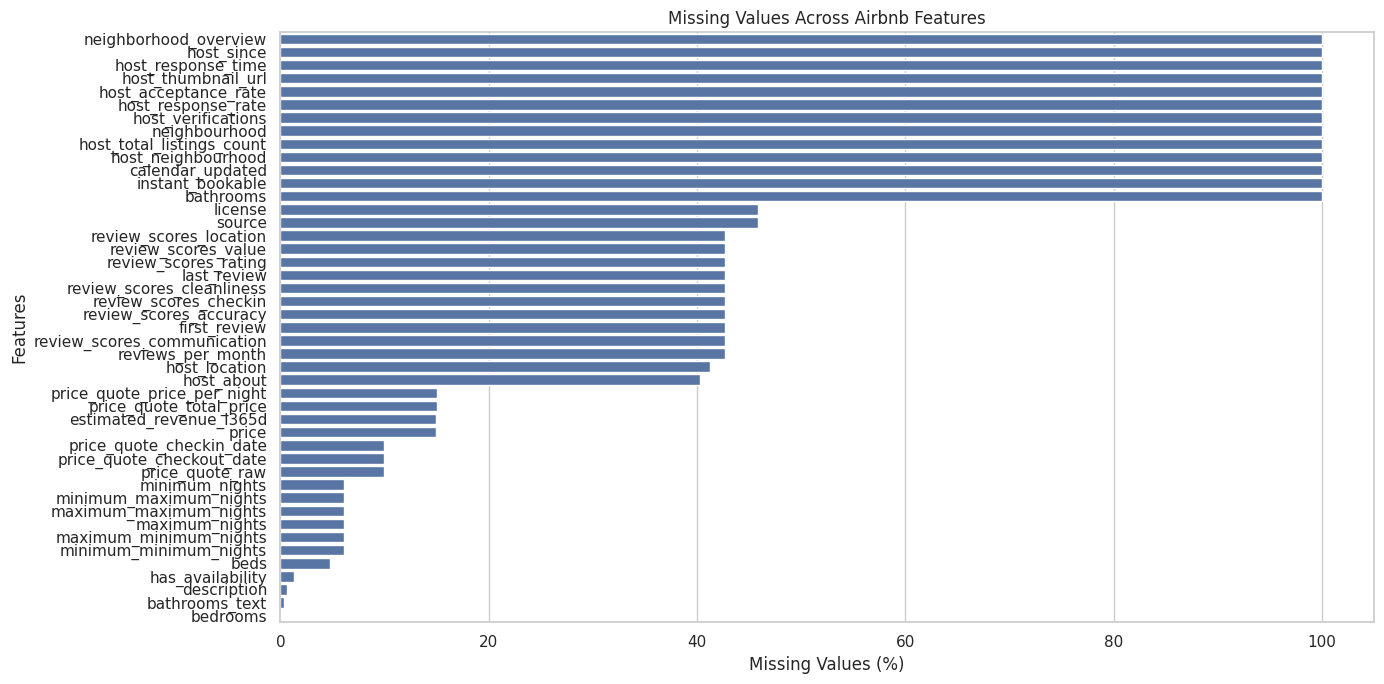

In [16]:

# Visualizing missing values

plt.figure(figsize=(14, 7))

missing_percent = (
    df_clean.isnull().mean() * 100
).sort_values(ascending=False)

missing_percent = missing_percent[missing_percent > 0]

sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index
)

plt.title("Missing Values Across Airbnb Features")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [17]:

# ==========================================
# STEP 3.6: PRICE DATA CLEANING
# ==========================================

if "price" in df_clean.columns:

    # Convert price into numeric format
    df_clean["price"] = (
        df_clean["price"]
        .astype(str)
        .str.replace(r"[$,]", "", regex=True)
    )

    df_clean["price"] = pd.to_numeric(
        df_clean["price"],
        errors="coerce"
    )

    print("Price column converted successfully!")

    print("\nPrice data type:")
    print(df_clean["price"].dtype)

    print("\nPrice summary:")
    print(df_clean["price"].describe())

else:
    print("Price column is not available!")


Price column converted successfully!

Price data type:
float64

Price summary:
count     2728.000000
mean       277.327375
std        494.480155
min          0.220000
25%         99.952500
50%        202.770000
75%        333.077500
max      13000.000000
Name: price, dtype: float64


In [18]:

# Converting selected columns to numeric data types

numeric_columns = [
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms",
    "minimum_nights",
    "maximum_nights",
    "availability_30",
    "availability_60",
    "availability_90",
    "availability_365",
    "number_of_reviews",
    "reviews_per_month",
    "review_scores_rating",
    "calculated_host_listings_count"
]

for column in numeric_columns:
    if column in df_clean.columns:
        df_clean[column] = pd.to_numeric(
            df_clean[column],
            errors="coerce"
        )

print("Numerical columns processed successfully!")


Numerical columns processed successfully!


In [19]:

# ==========================================
# STEP 3.7: INVALID VALUE DETECTION
# ==========================================

if "price" in df_clean.columns:
    print("Invalid prices:",
          (df_clean["price"] <= 0).sum())

if "accommodates" in df_clean.columns:
    print("Invalid guest capacity:",
          (df_clean["accommodates"] <= 0).sum())

if "minimum_nights" in df_clean.columns:
    print("Invalid minimum nights:",
          (df_clean["minimum_nights"] <= 0).sum())

if "number_of_reviews" in df_clean.columns:
    print("Invalid review counts:",
          (df_clean["number_of_reviews"] < 0).sum())

if "availability_365" in df_clean.columns:
    print("Invalid availability:",
          ((df_clean["availability_365"] < 0) |
           (df_clean["availability_365"] > 365)).sum())


Invalid prices: 0
Invalid guest capacity: 0
Invalid minimum nights: 0
Invalid review counts: 0
Invalid availability: 0


In [20]:

# ==========================================
# REMOVE INVALID RECORDS
# ==========================================

before_cleaning = len(df_clean)

# Price must be positive
if "price" in df_clean.columns:
    df_clean = df_clean[
        df_clean["price"].notna() &
        (df_clean["price"] > 0)
    ]

# Guest capacity must be positive
if "accommodates" in df_clean.columns:
    df_clean = df_clean[
        df_clean["accommodates"].isna() |
        (df_clean["accommodates"] > 0)
    ]

# Minimum nights cannot be negative
if "minimum_nights" in df_clean.columns:
    df_clean = df_clean[
        df_clean["minimum_nights"].isna() |
        (df_clean["minimum_nights"] >= 0)
    ]

# Review counts cannot be negative
if "number_of_reviews" in df_clean.columns:
    df_clean = df_clean[
        df_clean["number_of_reviews"].isna() |
        (df_clean["number_of_reviews"] >= 0)
    ]

# Availability must be between 0 and 365
if "availability_365" in df_clean.columns:
    df_clean = df_clean[
        df_clean["availability_365"].isna() |
        df_clean["availability_365"].between(0, 365)
    ]

print("Records before validation:", before_cleaning)
print("Records after validation:", len(df_clean))
print("Invalid records removed:",
      before_cleaning - len(df_clean))


Records before validation: 3208
Records after validation: 2728
Invalid records removed: 480


In [21]:

# ==========================================
# STEP 3.8: OUTLIER DETECTION USING IQR
# ==========================================

if "price" in df_clean.columns:

    Q1 = df_clean["price"].quantile(0.25)
    Q3 = df_clean["price"].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean["price"] < lower_bound) |
        (df_clean["price"] > upper_bound)
    ]

    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)

    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)

    print("Number of price outliers:", len(outliers))

    print(
        "Percentage of price outliers:",
        round(len(outliers) / len(df_clean) * 100, 2),
        "%"
    )


Q1: 99.9525
Q3: 333.0775
IQR: 233.125
Lower bound: -249.735
Upper bound: 682.765
Number of price outliers: 134
Percentage of price outliers: 4.91 %


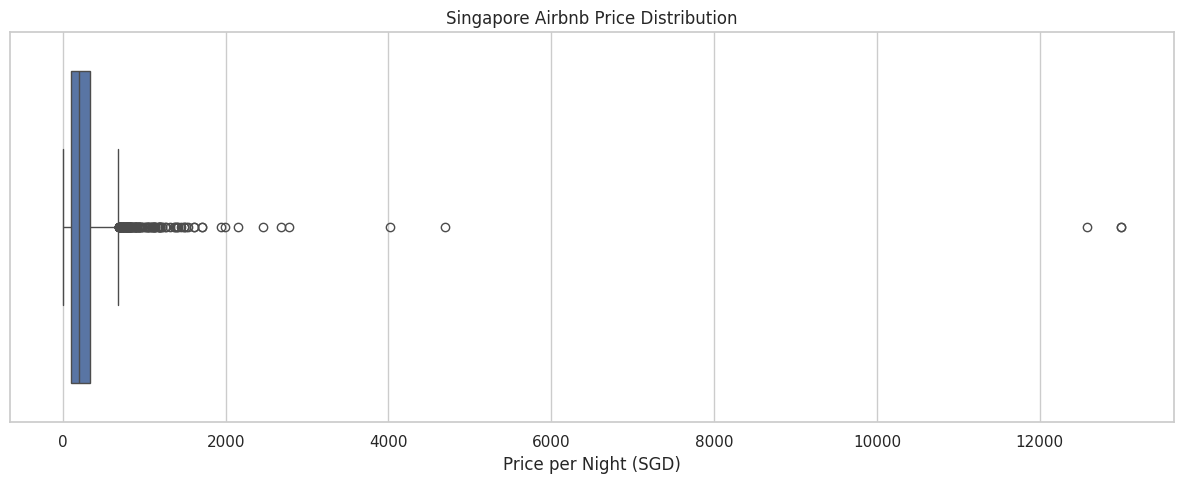

In [22]:

# Price distribution before outlier treatment

plt.figure(figsize=(12, 5))

sns.boxplot(x=df_clean["price"])

plt.title("Singapore Airbnb Price Distribution")
plt.xlabel("Price per Night (SGD)")
plt.tight_layout()
plt.show()


In [23]:

# ==========================================
# STEP 3.9: FINAL DATA QUALITY CHECK
# ==========================================

print("========== CLEANED DATASET REPORT ==========")

print("\nOriginal records:", len(df))
print("Cleaned records:", len(df_clean))

print("\nRemaining duplicate rows:",
      df_clean.duplicated().sum())

print("\nRemaining duplicate IDs:",
      df_clean["id"].duplicated().sum()
      if "id" in df_clean.columns else "ID unavailable")

print("\nRemaining missing values:",
      df_clean.isnull().sum().sum())

print("\nCleaned dataset dimensions:", df_clean.shape)

print("\nFinal data types:")
print(df_clean.dtypes)


========== CLEANED DATASET REPORT ==========

Original records: 3208
Cleaned records: 2728

Remaining duplicate rows: 0

Remaining duplicate IDs: 0

Remaining missing values: 53040

Cleaned dataset dimensions: (2728, 90)

Final data types:
id                                                int64
listing_url                                      object
scrape_id                                         int64
last_scraped                                     object
source                                           object
name                                             object
description                                      object
neighborhood_overview                           float64
picture_url                                      object
host_id                                           int64
host_url                                         object
host_profile_id                                   int64
host_profile_url                                 object
host_name                       

In [24]:

# ==========================================
# STEP 3.10: SAVE CLEANED DATASET
# ==========================================

cleaned_file = PROCESSED_DIR / "singapore_airbnb_cleaned.csv"

df_clean.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", cleaned_file)
print("Final records:", len(df_clean))


Cleaned dataset saved successfully!
File location: /data/processed/singapore_airbnb_cleaned.csv
Final records: 2728


In [25]:

# ==========================================
# DATA CLEANING SUMMARY
# ==========================================

cleaning_summary = pd.DataFrame({
    "Metric": [
        "Original Records",
        "Cleaned Records",
        "Records Removed",
        "Original Features",
        "Remaining Features",
        "Remaining Duplicate Rows",
        "Remaining Missing Values"
    ],

    "Value": [
        len(df),
        len(df_clean),
        len(df) - len(df_clean),
        df.shape[1],
        df_clean.shape[1],
        df_clean.duplicated().sum(),
        df_clean.isnull().sum().sum()
    ]
})

display(cleaning_summary)

cleaning_summary.to_csv(
    PROCESSED_DIR / "cleaning_summary.csv",
    index=False
)


,Metric,Value
0,Original Records,3208
1,Cleaned Records,2728
2,Records Removed,480
3,Original Features,90
4,Remaining Features,90
5,Remaining Duplicate Rows,0
6,Remaining Missing Values,53040


In [26]:
print("Cleaned shape:", df_clean.shape)
print("\nPrice statistics:")
print(df_clean["price"].describe())

print("\nTop missing columns:")
print(
    df_clean.isnull().sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nCleaning summary:")
display(cleaning_summary)

Cleaned shape: (2728, 90)

Price statistics:
count     2728.000000
mean       277.327375
std        494.480155
min          0.220000
25%         99.952500
50%        202.770000
75%        333.077500
max      13000.000000
Name: price, dtype: float64

Top missing columns:
neighborhood_overview        2728
host_since                   2728
host_response_time           2728
host_thumbnail_url           2728
host_acceptance_rate         2728
host_response_rate           2728
host_verifications           2728
neighbourhood                2728
host_total_listings_count    2728
host_neighbourhood           2728
dtype: int64

Cleaning summary:


,Metric,Value
0,Original Records,3208
1,Cleaned Records,2728
2,Records Removed,480
3,Original Features,90
4,Remaining Features,90
5,Remaining Duplicate Rows,0
6,Remaining Missing Values,53040


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Create a separate dataset for EDA
eda_df = df_clean.copy()

print("EDA dataset shape:", eda_df.shape)

EDA dataset shape: (2728, 90)


In [29]:
missing_values = eda_df.isnull().sum()

missing_percentage = (
    missing_values / len(eda_df)
) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

missing_report = missing_report.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_report.head(20))

,Missing Values,Missing Percentage
neighborhood_overview,2728,100.000000
host_since,2728,100.000000
host_response_time,2728,100.000000
host_thumbnail_url,2728,100.000000
host_acceptance_rate,2728,100.000000
host_response_rate,2728,100.000000
host_verifications,2728,100.000000
neighbourhood,2728,100.000000
host_total_listings_count,2728,100.000000
host_neighbourhood,2728,100.000000


In [30]:
missing_values = eda_df.isnull().sum()

missing_percentage = (
    missing_values / len(eda_df)
) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

missing_report = missing_report.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_report.head(20))

,Missing Values,Missing Percentage
neighborhood_overview,2728,100.000000
host_since,2728,100.000000
host_response_time,2728,100.000000
host_thumbnail_url,2728,100.000000
host_acceptance_rate,2728,100.000000
host_response_rate,2728,100.000000
host_verifications,2728,100.000000
neighbourhood,2728,100.000000
host_total_listings_count,2728,100.000000
host_neighbourhood,2728,100.000000


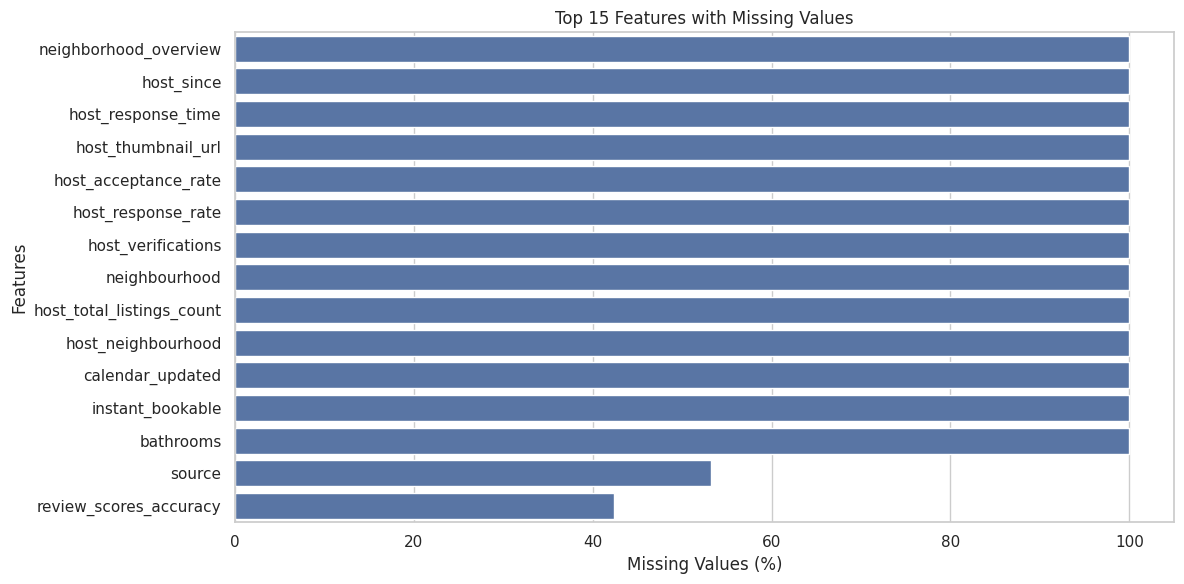

In [31]:
top_missing = missing_report.head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_missing["Missing Percentage"],
    y=top_missing.index
)

plt.title("Top 15 Features with Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [32]:
print("Lowest 20 prices:")
display(eda_df["price"].nsmallest(20))

print("Highest 20 prices:")
display(eda_df["price"].nlargest(20))

print("\nPrice percentiles:")
display(
    eda_df["price"].quantile(
        [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1]
    )
)

Lowest 20 prices:


,price
895,0.22
268,19.69
552,23.49
1339,24.82
537,24.86
551,24.96
698,27.53
43,27.84
180,27.84
535,27.84


Highest 20 prices:


,price
931,13000.00
932,13000.00
2065,12585.14
741,4690.19
1418,4019.38
565,2773.00
1422,2676.31
1378,2458.00
92,2156.68
2745,1995.00



Price percentiles:


,price
0.00,0.2200
0.01,33.6900
0.05,43.9635
0.25,99.9525
0.50,202.7700
0.75,333.0775
0.95,678.4505
0.99,1244.9000
1.00,13000.0000


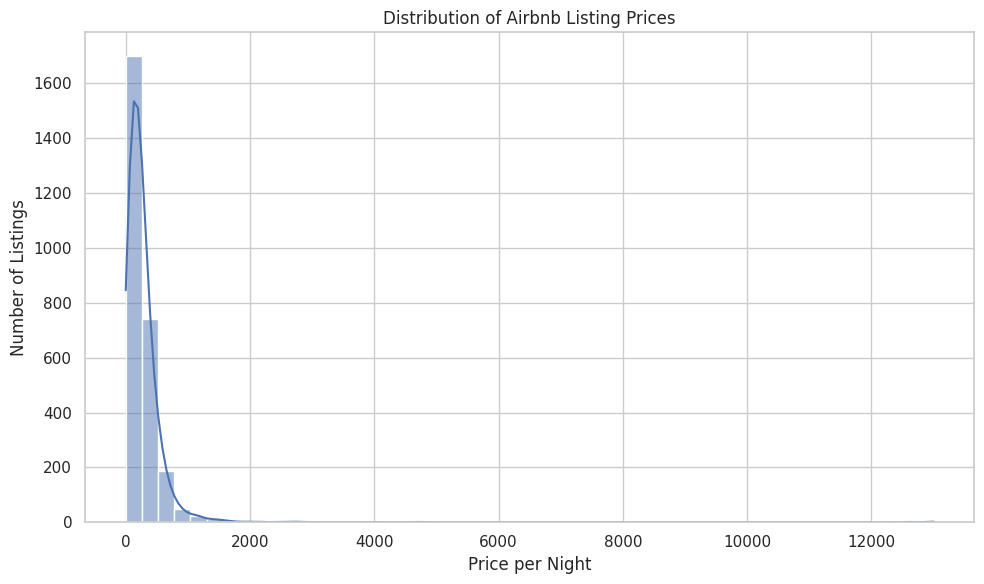

In [33]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=eda_df,
    x="price",
    bins=50,
    kde=True
)

plt.title("Distribution of Airbnb Listing Prices")
plt.xlabel("Price per Night")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

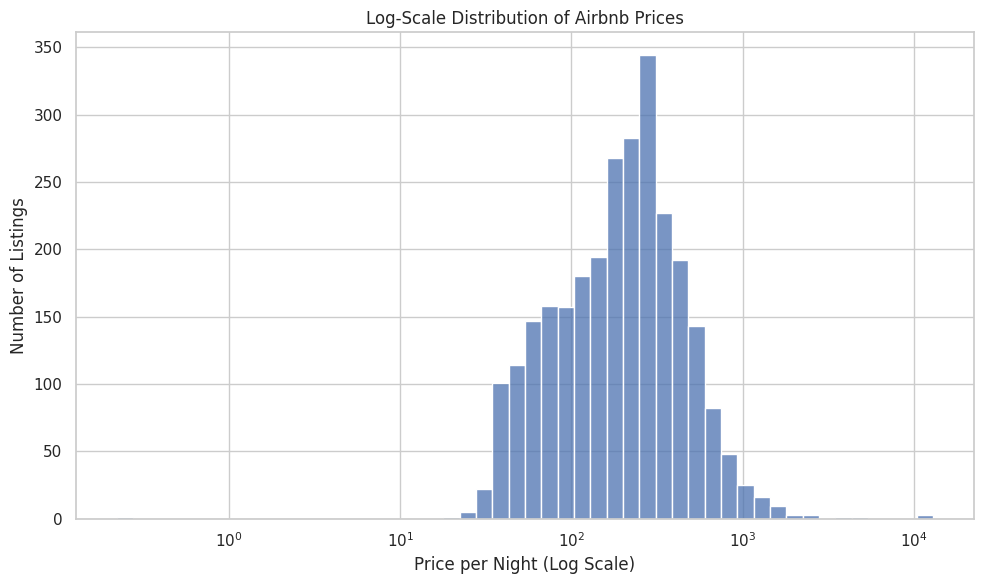

In [34]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=eda_df,
    x="price",
    bins=50,
    log_scale=True
)

plt.title("Log-Scale Distribution of Airbnb Prices")
plt.xlabel("Price per Night (Log Scale)")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

,count
room_type,
Private room,1508
Entire home/apt,1084
Hotel room,74
Shared room,62


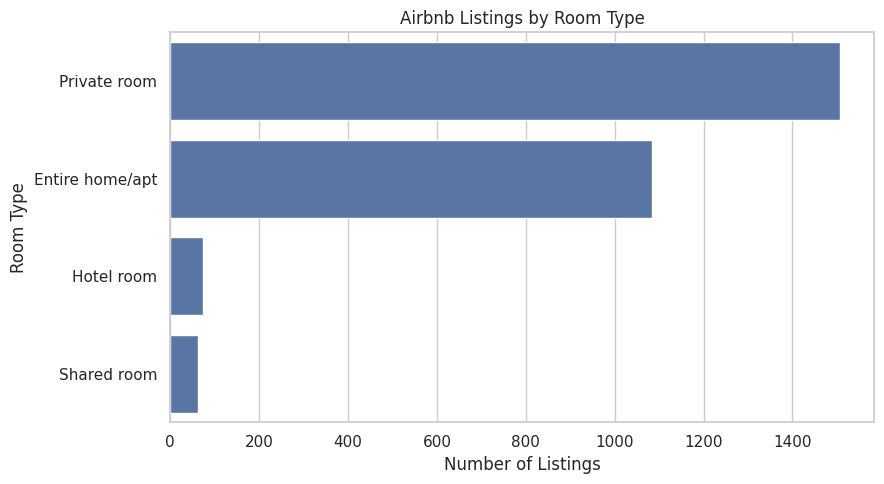

In [35]:
room_counts = eda_df["room_type"].value_counts()

display(room_counts)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=eda_df,
    y="room_type",
    order=room_counts.index
)

plt.title("Airbnb Listings by Room Type")
plt.xlabel("Number of Listings")
plt.ylabel("Room Type")
plt.tight_layout()
plt.show()

In [36]:
room_percentage = (
    eda_df["room_type"].value_counts(normalize=True) * 100
)

display(room_percentage.round(2))

,proportion
room_type,
Private room,55.28
Entire home/apt,39.74
Hotel room,2.71
Shared room,2.27


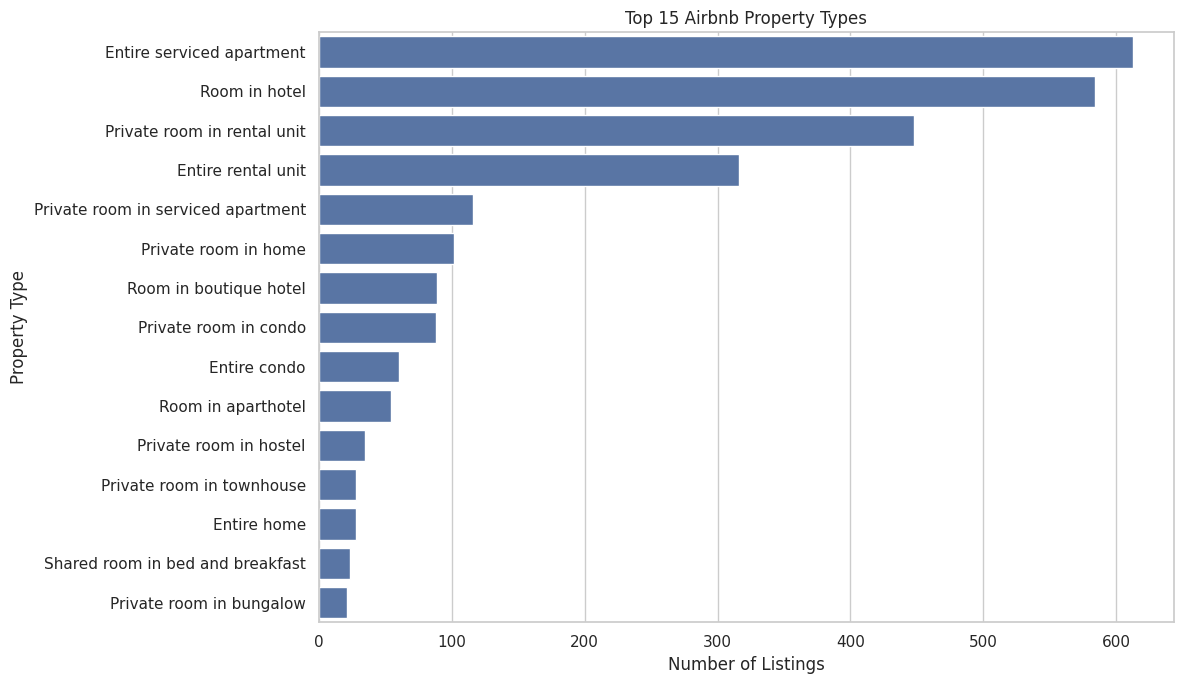

In [37]:
property_counts = eda_df["property_type"].value_counts().head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=property_counts.values,
    y=property_counts.index
)

plt.title("Top 15 Airbnb Property Types")
plt.xlabel("Number of Listings")
plt.ylabel("Property Type")
plt.tight_layout()
plt.show()

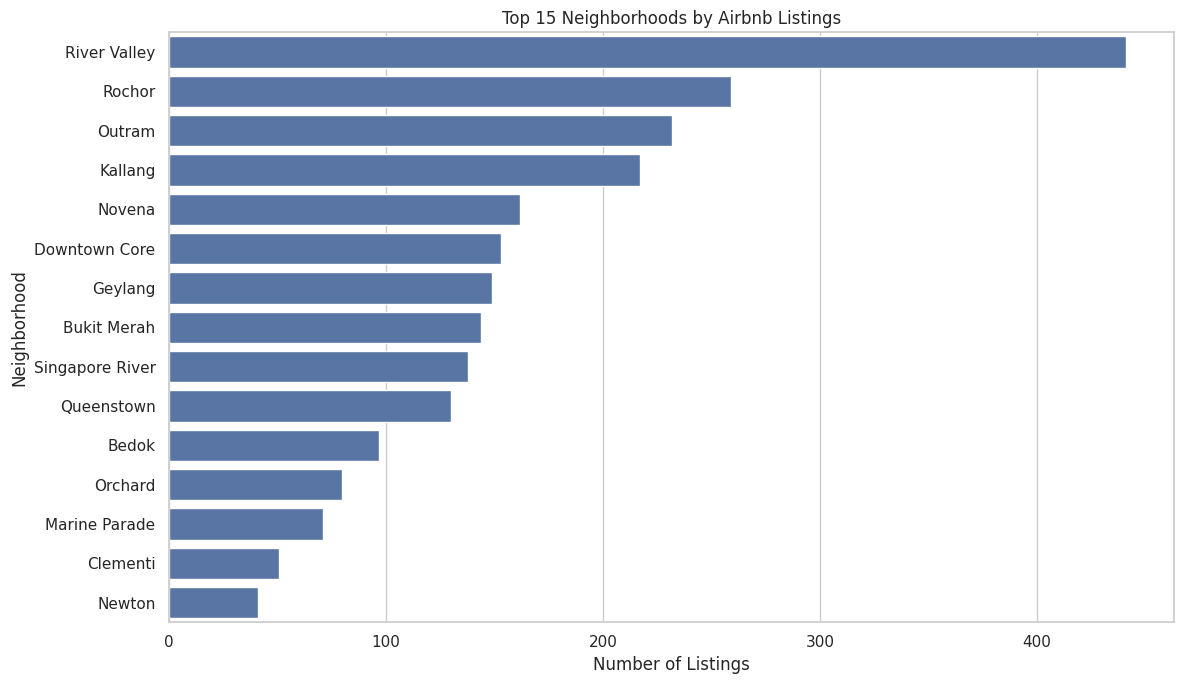

In [38]:
neighborhood_counts = (
    eda_df["neighbourhood_cleansed"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=neighborhood_counts.values,
    y=neighborhood_counts.index
)

plt.title("Top 15 Neighborhoods by Airbnb Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Neighborhood")
plt.tight_layout()
plt.show()

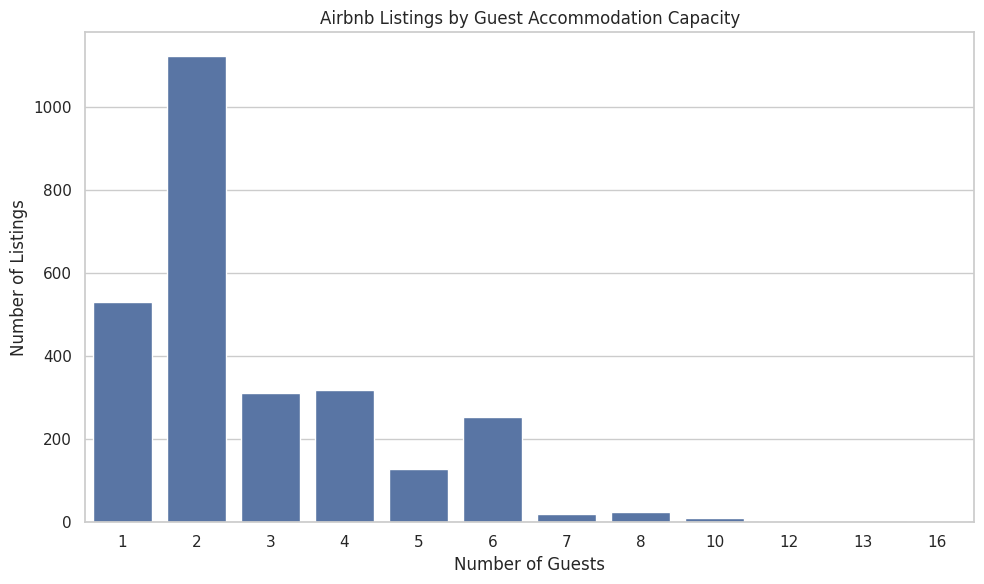

In [39]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=eda_df,
    x="accommodates",
    order=sorted(eda_df["accommodates"].dropna().unique())
)

plt.title("Airbnb Listings by Guest Accommodation Capacity")
plt.xlabel("Number of Guests")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

In [40]:
availability_columns = [
    "availability_30",
    "availability_60",
    "availability_90",
    "availability_365"
]

availability_summary = eda_df[availability_columns].describe().T

display(availability_summary)

,count,mean,std,min,25%,50%,75%,max
availability_30,2728.0,19.483504,10.838266,0.0,13.0,24.0,29.0,30.0
availability_60,2728.0,43.768328,20.777318,0.0,39.0,53.0,59.0,60.0
availability_90,2728.0,67.461877,29.833999,0.0,62.0,81.0,89.0,90.0
availability_365,2728.0,286.876833,110.479690,0.0,262.0,345.0,362.0,365.0


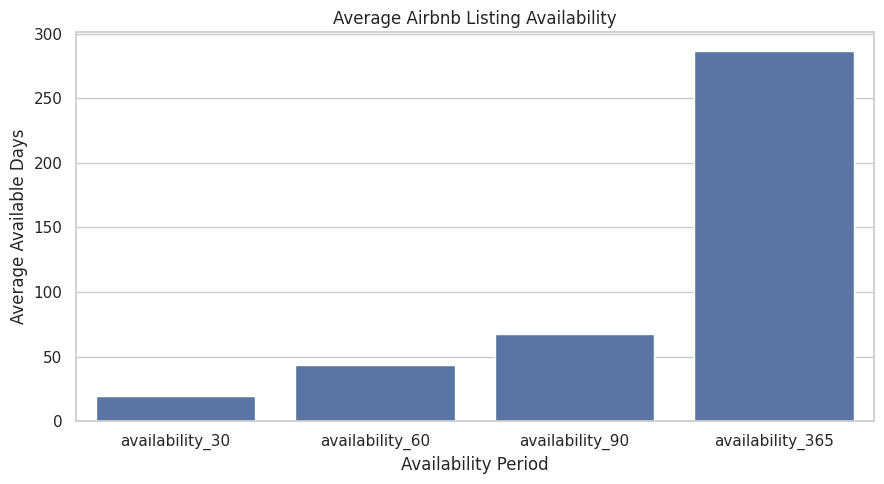

In [41]:
availability_means = eda_df[availability_columns].mean()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=availability_means.index,
    y=availability_means.values
)

plt.title("Average Airbnb Listing Availability")
plt.xlabel("Availability Period")
plt.ylabel("Average Available Days")
plt.tight_layout()
plt.show()

In [42]:
review_columns = [
    "number_of_reviews",
    "reviews_per_month",
    "review_scores_rating"
]

display(eda_df[review_columns].describe())

,number_of_reviews,reviews_per_month,review_scores_rating
count,2728.000000,1572.00000,1572.000000
mean,14.783358,0.82264,4.530827
std,58.717696,2.18234,0.609066
min,0.000000,0.01000,1.000000
25%,0.000000,0.06000,4.330000
50%,1.000000,0.18000,4.710000
75%,8.000000,0.70000,5.000000
max,1519.000000,46.60000,5.000000


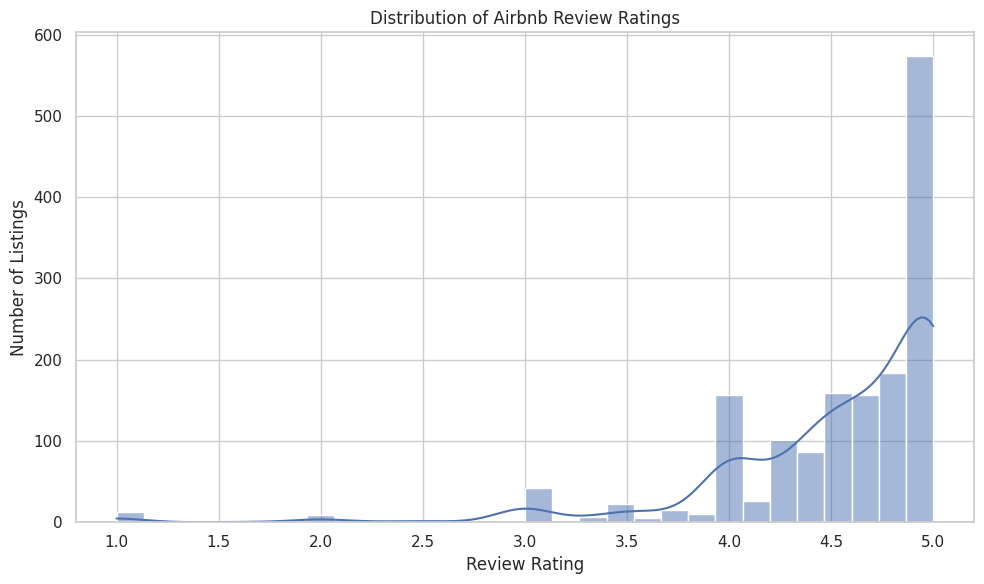

In [43]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=eda_df,
    x="review_scores_rating",
    bins=30,
    kde=True
)

plt.title("Distribution of Airbnb Review Ratings")
plt.xlabel("Review Rating")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

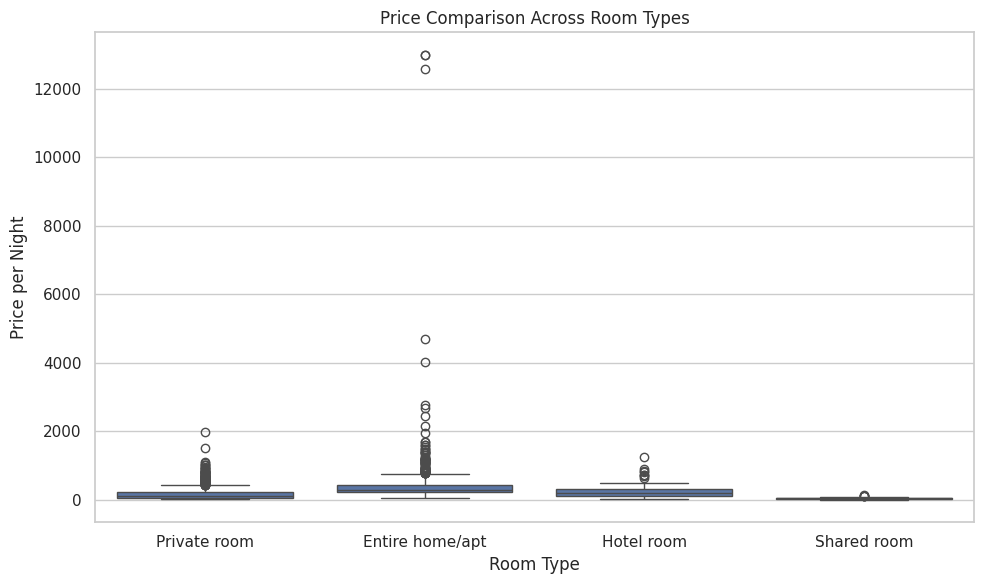

In [44]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=eda_df,
    x="room_type",
    y="price"
)

plt.title("Price Comparison Across Room Types")
plt.xlabel("Room Type")
plt.ylabel("Price per Night")
plt.tight_layout()
plt.show()

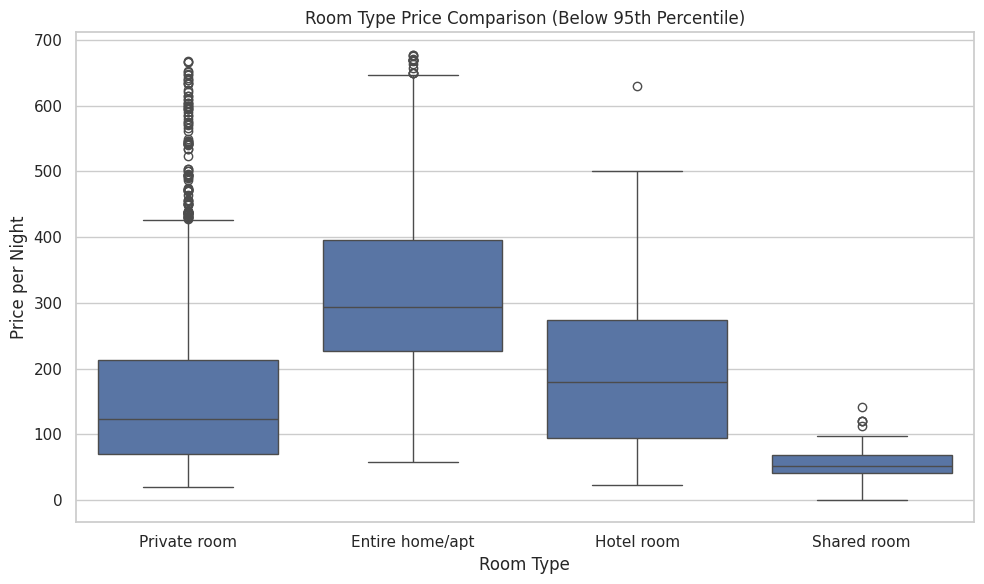

In [45]:
price_limit = eda_df["price"].quantile(0.95)

price_view = eda_df[
    eda_df["price"] <= price_limit
]

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=price_view,
    x="room_type",
    y="price"
)

plt.title("Room Type Price Comparison (Below 95th Percentile)")
plt.xlabel("Room Type")
plt.ylabel("Price per Night")
plt.tight_layout()
plt.show()

In [46]:
# Remove columns containing only missing values
eda_df = eda_df.dropna(axis=1, how="all")

print("Updated EDA dataset shape:", eda_df.shape)

Updated EDA dataset shape: (2728, 77)


In [47]:
# Analyze Airbnb listing prices
print("Price Statistics:")
print(eda_df["price"].describe())

print("\nLowest 10 Prices:")
print(eda_df["price"].nsmallest(10))

print("\nHighest 10 Prices:")
print(eda_df["price"].nlargest(10))

Price Statistics:
count     2728.000000
mean       277.327375
std        494.480155
min          0.220000
25%         99.952500
50%        202.770000
75%        333.077500
max      13000.000000
Name: price, dtype: float64

Lowest 10 Prices:
895      0.22
268     19.69
552     23.49
1339    24.82
537     24.86
551     24.96
698     27.53
43      27.84
180     27.84
535     27.84
Name: price, dtype: float64

Highest 10 Prices:
931     13000.00
932     13000.00
2065    12585.14
741      4690.19
1418     4019.38
565      2773.00
1422     2676.31
1378     2458.00
92       2156.68
2745     1995.00
Name: price, dtype: float64


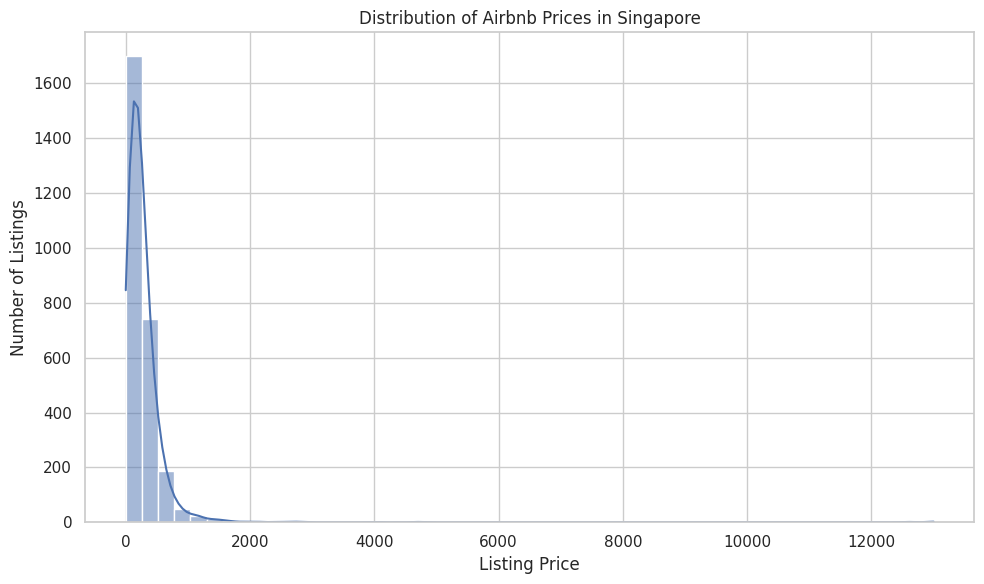

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(
    data=eda_df,
    x="price",
    bins=50,
    kde=True
)

plt.title("Distribution of Airbnb Prices in Singapore")
plt.xlabel("Listing Price")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()

In [49]:
# Investigate extreme listing prices
extreme_listings = eda_df[
    (eda_df["price"] < 20) |
    (eda_df["price"] > 5000)
]

columns_to_show = [
    "id",
    "name",
    "room_type",
    "property_type",
    "neighbourhood_cleansed",
    "accommodates",
    "price"
]

display(
    extreme_listings[columns_to_show]
    .sort_values("price")
)

,id,name,room_type,property_type,neighbourhood_cleansed,accommodates,price
895,41406564,Get extra freeeeeeee stay when you find loopholes,Shared room,Shared room in cave,Bedok,1,0.22
268,16578603,Cosy single bedroom in Yishun SGP,Private room,Private room in rental unit,Yishun,1,19.69
2065,1254334294650326595,Clean,Entire home/apt,Entire home,Bukit Panjang,6,12585.14
931,42555446,"Citadines Mount Sophia Singapore, Studio Execu...",Entire home/apt,Entire serviced apartment,Rochor,2,13000.00
932,42555518,"Citadines Mount Sophia, 1 Bedroom Deluxe Apt",Entire home/apt,Entire serviced apartment,Rochor,3,13000.00


In [50]:
room_counts = eda_df["room_type"].value_counts()

room_percentages = (
    eda_df["room_type"].value_counts(normalize=True) * 100
)

room_summary = pd.DataFrame({
    "Number of Listings": room_counts,
    "Percentage (%)": room_percentages.round(2)
})

display(room_summary)

,Number of Listings,Percentage (%)
room_type,,
Private room,1508,55.28
Entire home/apt,1084,39.74
Hotel room,74,2.71
Shared room,62,2.27


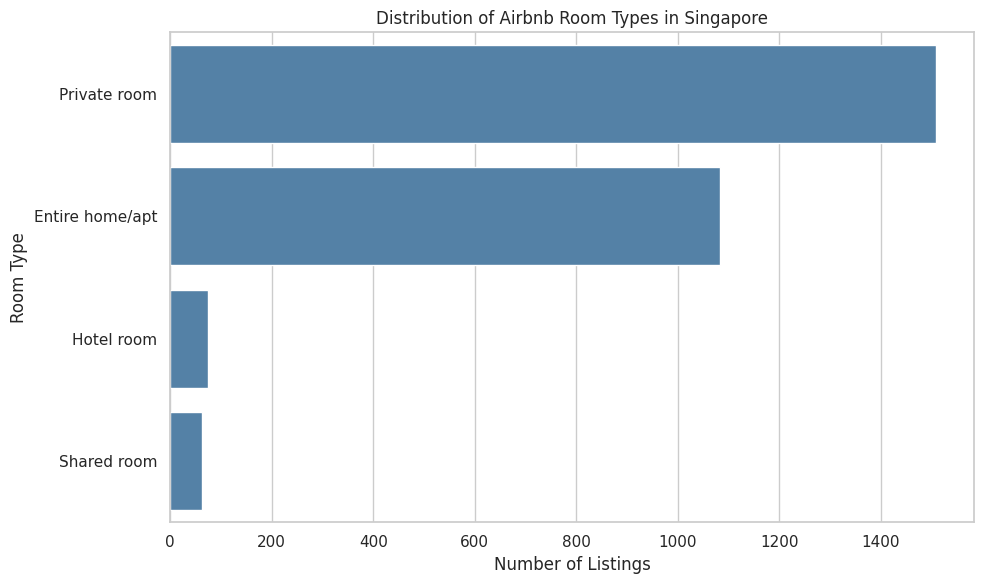

In [51]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=eda_df,
    y="room_type",
    order=eda_df["room_type"].value_counts().index,
    color="steelblue"
)

plt.title("Distribution of Airbnb Room Types in Singapore")
plt.xlabel("Number of Listings")
plt.ylabel("Room Type")

plt.tight_layout()
plt.show()

In [52]:
room_price_summary = (
    eda_df.groupby("room_type")["price"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .sort_values("median", ascending=False)
)

display(room_price_summary)

,count,mean,median,min,max
room_type,,,,,
Entire home/apt,1084,423.58,304.28,57.24,13000.0
Hotel room,74,254.37,189.50,23.49,1253.0
Private room,1508,182.30,126.72,19.69,1995.0
Shared room,62,58.99,51.50,0.22,141.0


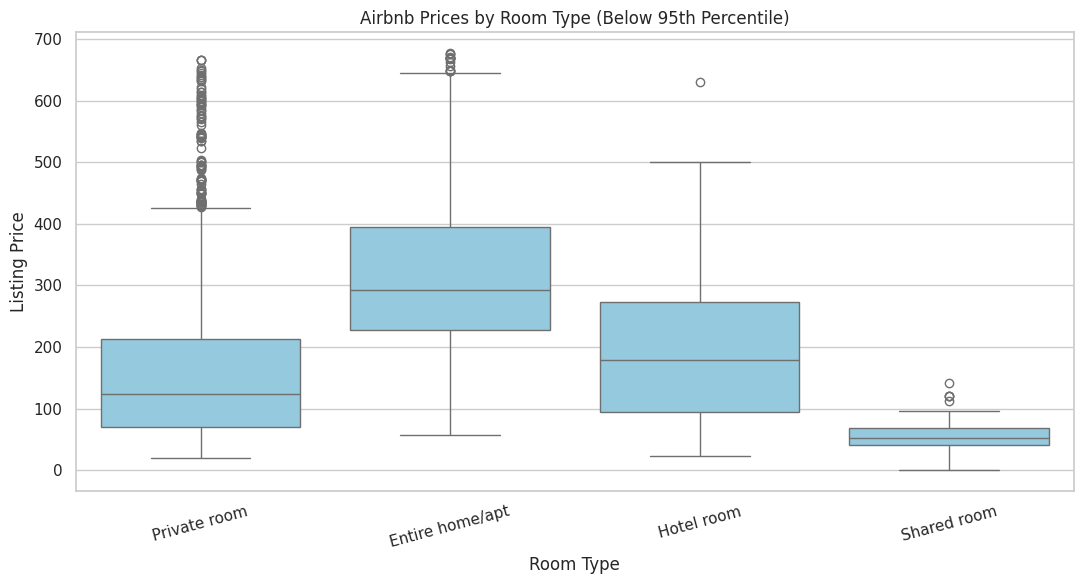

In [53]:
# Restrict only the visualization to the 95th percentile
price_limit = eda_df["price"].quantile(0.95)

plot_df = eda_df[eda_df["price"] <= price_limit]

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=plot_df,
    x="room_type",
    y="price",
    color="skyblue"
)

plt.title("Airbnb Prices by Room Type (Below 95th Percentile)")
plt.xlabel("Room Type")
plt.ylabel("Listing Price")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()